# Cold Chain AI: Early Warning System

## 1. Dataset Loading

This project aims to develop an intelligent early warning system for cold storage conditions using deep learning.

The system analyzes temperature and humidity measurements collected from multiple sensors over time to identify patterns that may indicate a temperature excursion risk.

In this notebook, the dataset will be loaded and inspected before performing data preprocessing and exploratory analysis.

In [ ]:
import pandas as pd
import numpy as np
import os
import zipfile
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving experiment_actions (1).csv to experiment_actions (1).csv
Saving Preprocessed.zip to Preprocessed.zip
Saving Raw.zip to Raw.zip
Saving overview.csv to overview.csv


In [ ]:
print("Files in Colab:")

for file in os.listdir("/content"):
    print(file)

Files in Colab:
.config
Raw.zip
experiment_actions (1).csv
overview.csv
Preprocessed.zip
sample_data


## 2. Dataset Description

The dataset contains temperature and humidity measurements collected from nine sensors installed in a cold storage room.

The dataset also includes an overview file and an experiment actions file containing recorded events during the experiment.

The sensor measurements are time-dependent, making the dataset suitable for time-series analysis and deep learning models such as LSTM and GRU.

In [ ]:
overview = pd.read_csv("/content/overview.csv", sep=";")

print("Dataset overview shape:", overview.shape)
print("\nColumns:")
print(overview.columns.tolist())

print("\nFirst 10 rows:")
display(overview.head(10))

Dataset overview shape: (42, 10)

Columns:
['Sensor', 'SENSOR01', 'SENSOR02', 'SENSOR03', 'SENSOR04', 'SENSOR05', 'SENSOR06', 'SENSOR07', 'SENSOR08', 'SENSOR09']

First 10 rows:


,Sensor,SENSOR01,SENSOR02,SENSOR03,SENSOR04,SENSOR05,SENSOR06,SENSOR07,SENSOR08,SENSOR09
0,Start,2024-09-02 09:26:30,2024-09-02 09:26:20,2024-09-02 09:27:50,2024-09-02 09:28:45,2024-09-09 16:13:15,2024-09-02 09:31:55,2024-09-02 09:33:30,2024-09-02 09:35:25,2024-09-09 14:00:00
1,End,2024-09-11 11:28:30,2024-09-11 11:27:55,2024-09-11 11:24:55,2024-09-11 03:32:40,2024-09-11 11:28:40,2024-09-11 11:25:45,2024-09-11 11:27:10,2024-09-11 11:27:15,2024-09-11 11:26:20
2,Missing Start,2024-09-09 07:04:15,NaN,2024-09-02 09:35:25,2024-09-11 03:32:45,2024-09-02 09:35:25,NaN,NaN,NaN,2024-09-02 09:35:25
3,Missing End,2024-09-09 08:24:40,NaN,2024-09-06 14:07:55,2024-09-11 11:24:55,2024-09-09 16:13:10,NaN,NaN,NaN,2024-09-09 13:59:55
4,Length,155869,156835,84444,151168,31101,156835,156835,156835,32700
5,Temperature min,5.3,5.8,4.8,5.6,6.9,5.1,6.0,9.0,5.4
6,Temperature max,42.2,38.7,12.3,21.9,13.3,22.1,22.8,22.3,12.7
7,Temperature mean,11.339025078752028,11.93497624892403,6.543491544692341,8.358605657281965,8.242976110092924,7.793736729684061,8.534433002837376,11.685301750247076,7.318663608562692
8,Temperature std,5.774035289650634,6.4194578886727625,1.437902582028186,2.162755631882654,1.2638602395774945,2.1571694396864025,2.1122837744091054,2.086379688788388,1.612791003962473
9,Temperature q25,6.5,6.8,5.7,6.5,7.4,6.0,6.7,9.9,6.2


## 3. Dataset Overview

The overview file provides summary information for the nine sensors, from **SENSOR01 to SENSOR09**.

It contains **42 rows and 10 columns**, including information about the recording period, number of measurements, and temperature statistics for each sensor.

The number of measurements varies between sensors. The recorded temperature ranges also differ across sensors. For example, SENSOR01 has a temperature range from **5.3°C to 42.2°C**, while SENSOR05 ranges from **6.9°C to 13.3°C**.

These differences indicate variation in the environmental conditions recorded by the sensors. Therefore, the raw sensor data will be inspected and cleaned individually before being combined into the time-series dataset used for Deep Learning.

## 4. Loading the Raw Sensor Data

The raw sensor dataset is extracted from the ZIP file so that the individual sensor files can be accessed and processed.

The raw data will be used for detailed inspection, data quality checking, cleaning, and time-series preparation before training the Deep Learning model.

In [ ]:
raw_zip = "/content/Raw.zip"
raw_extract_path = "/content/raw_data"

with zipfile.ZipFile(raw_zip, "r") as zip_ref:
    zip_ref.extractall(raw_extract_path)

print("Raw dataset extracted successfully.")

Raw dataset extracted successfully.


In [ ]:
print("Raw dataset files:")

for file in os.listdir(raw_extract_path):
    print(file)

Raw dataset files:
SENSOR03.CSV
SENSOR01.CSV
SENSOR06.CSV
SENSOR09.CSV
SENSOR05.CSV
SENSOR08.CSV
SENSOR02.CSV
SENSOR07.CSV
SENSOR04.CSV


## 4. Raw Sensor Data

The raw dataset contains measurements collected from **nine sensors** installed in the cold storage room.

Each sensor is stored in a separate CSV file, from **SENSOR01.CSV** to **SENSOR09.CSV**.

The raw sensor files contain time-dependent environmental measurements that will be inspected individually before performing data cleaning and preprocessing.

This step helps identify the structure of the sensor data and detect potential data-quality issues before preparing the data for time-series modeling.

In [ ]:
sensor01_path = "/content/raw_data/SENSOR01.CSV"

sensor01 = pd.read_csv(
    sensor01_path,
    sep=";",
    dtype=str,
    low_memory=False
)

print("Shape:", sensor01.shape)

print("\nColumns:")
print(sensor01.columns.tolist())

print("\nFirst 10 rows:")
display(sensor01.head(10))

Shape: (156020, 4)

Columns:
['Date', 'Time', 'Temperature (C)', 'Humidity (%)']

First 10 rows:


,Date,Time,Temperature (C),Humidity (%)
0,02.09.2024,09:26:30,21.40,57.40
1,02.09.2024,09:26:35,21.30,59.20
2,02.09.2024,09:26:40,21.30,59.00
3,02.09.2024,09:26:45,21.30,59.00
4,02.09.2024,09:26:50,21.20,59.30
5,02.09.2024,09:26:55,21.30,59.50
6,02.09.2024,09:27:00,21.20,59.50
7,02.09.2024,09:27:05,21.20,59.70
8,02.09.2024,09:27:10,21.20,60.20
9,02.09.2024,09:27:15,21.20,60.20


## 5. Inspecting the Raw Sensor Data

SENSOR01 contains **156,020 rows** and **4 columns**:

- `Date`
- `Time`
- `Temperature (C)`
- `Humidity (%)`

The first observations show that the sensor records measurements at regular **5-second intervals**.

For example, the first recorded measurement is on **02.09.2024 at 09:26:30**, with a temperature of **21.40°C** and humidity of **57.40%**.

The data is initially loaded as strings so that the raw values can be inspected before converting them to the appropriate data types during the cleaning process.

The presence of separate date and time columns also means that they need to be combined into a single chronological DateTime variable for time-series analysis.

In [ ]:
print("Missing values in SENSOR01:")

print(sensor01.isna().sum())

Missing values in SENSOR01:
Date               0
Time               0
Temperature (C)    0
Humidity (%)       0
dtype: int64


## 6. Missing Values Inspection

The SENSOR01 dataset was checked for missing values in all four columns.

No missing values were detected in Date, Time, Temperature, or Humidity.

Therefore, no missing-value imputation is required for SENSOR01 at this stage.

In [ ]:
sensor_files = sorted([
    file for file in os.listdir(raw_extract_path)
    if file.upper().endswith(".CSV")
])

for file in sensor_files:
    path = os.path.join(raw_extract_path, file)

    df = pd.read_csv(
        path,
        sep=";",
        dtype=str,
        low_memory=False
    )

    print(
        file,
        "| Rows:", len(df),
        "| Missing values:", df.isna().sum().sum()
    )

SENSOR01.CSV | Rows: 156020 | Missing values: 0
SENSOR02.CSV | Rows: 156980 | Missing values: 0
SENSOR03.CSV | Rows: 84453 | Missing values: 0
SENSOR04.CSV | Rows: 151248 | Missing values: 0
SENSOR05.CSV | Rows: 31146 | Missing values: 0
SENSOR06.CSV | Rows: 156887 | Missing values: 0
SENSOR07.CSV | Rows: 156885 | Missing values: 0
SENSOR08.CSV | Rows: 156863 | Missing values: 0
SENSOR09.CSV | Rows: 32717 | Missing values: 0


## 7. Repeated Header Inspection

The raw sensor files were inspected for repeated header rows.

Repeated headers can appear inside a CSV file and may cause problems when converting temperature and humidity values to numeric data.

These rows will be identified and removed during preprocessing if they are present.

In [ ]:
for file in sensor_files:
    path = os.path.join(raw_extract_path, file)

    df = pd.read_csv(
        path,
        sep=";",
        dtype=str,
        low_memory=False
    )

    repeated_headers = (
        (df["Date"] == "Date") &
        (df["Time"] == "Time")
    ).sum()

    print(
        file,
        "| Rows:", len(df),
        "| Repeated headers:", repeated_headers
    )

SENSOR01.CSV | Rows: 156020 | Repeated headers: 1
SENSOR02.CSV | Rows: 156980 | Repeated headers: 0
SENSOR03.CSV | Rows: 84453 | Repeated headers: 3
SENSOR04.CSV | Rows: 151248 | Repeated headers: 0
SENSOR05.CSV | Rows: 31146 | Repeated headers: 0
SENSOR06.CSV | Rows: 156887 | Repeated headers: 0
SENSOR07.CSV | Rows: 156885 | Repeated headers: 0
SENSOR08.CSV | Rows: 156863 | Repeated headers: 0
SENSOR09.CSV | Rows: 32717 | Repeated headers: 0


## 8. Repeated Header Removal

Repeated header rows were found in **SENSOR01 (1 row)** and **SENSOR03 (3 rows)**.

These rows do not represent actual sensor measurements. They contain the column names repeated inside the dataset.

Therefore, the repeated header rows will be removed before converting the temperature and humidity columns to numeric values.

In [ ]:
cleaned_raw = {}

for file in sensor_files:
    path = os.path.join(raw_extract_path, file)

    df = pd.read_csv(
        path,
        sep=";",
        dtype=str,
        low_memory=False
    )

    before = len(df)

    repeated_header_mask = (
        (df["Date"] == "Date") &
        (df["Time"] == "Time")
    )

    df = df[~repeated_header_mask].copy()

    removed = before - len(df)

    sensor_name = file.replace(".CSV", "")

    cleaned_raw[sensor_name] = df.reset_index(drop=True)

    print(
        sensor_name,
        "| Before:", before,
        "| Removed:", removed,
        "| After:", len(df)
    )

SENSOR01 | Before: 156020 | Removed: 1 | After: 156019
SENSOR02 | Before: 156980 | Removed: 0 | After: 156980
SENSOR03 | Before: 84453 | Removed: 3 | After: 84450
SENSOR04 | Before: 151248 | Removed: 0 | After: 151248
SENSOR05 | Before: 31146 | Removed: 0 | After: 31146
SENSOR06 | Before: 156887 | Removed: 0 | After: 156887
SENSOR07 | Before: 156885 | Removed: 0 | After: 156885
SENSOR08 | Before: 156863 | Removed: 0 | After: 156863
SENSOR09 | Before: 32717 | Removed: 0 | After: 32717


## 9. Repeated Header Removal Results

The repeated header rows were successfully removed from the raw sensor files.

A total of **4 repeated header rows** were removed: **1 row from SENSOR01** and **3 rows from SENSOR03**.

No repeated header rows were found in the remaining sensors.

The cleaned sensor data is now stored in the `cleaned_raw` dictionary and is ready for further preprocessing and data-quality checks.

## 9. Numeric Data Conversion

The Temperature and Humidity columns are currently stored as text values.

They will be converted to numeric data types so that statistical analysis, visualization, scaling, and deep learning models can be applied correctly.

In [ ]:
for sensor_name, df in cleaned_raw.items():
    df["Temperature (C)"] = pd.to_numeric(
        df["Temperature (C)"],
        errors="coerce"
    )

    df["Humidity (%)"] = pd.to_numeric(
        df["Humidity (%)"],
        errors="coerce"
    )

    cleaned_raw[sensor_name] = df

print("Temperature and humidity converted to numeric values.")

Temperature and humidity converted to numeric values.


## 10. Missing Values After Numeric Conversion

After converting Temperature and Humidity to numeric values, the datasets are checked again for missing values.

This step ensures that non-numeric entries did not create missing values during the conversion process.

In [ ]:
for sensor_name, df in cleaned_raw.items():
    print(
        sensor_name,
        "| Temperature missing:",
        df["Temperature (C)"].isna().sum(),
        "| Humidity missing:",
        df["Humidity (%)"].isna().sum()
    )

SENSOR01 | Temperature missing: 0 | Humidity missing: 0
SENSOR02 | Temperature missing: 0 | Humidity missing: 0
SENSOR03 | Temperature missing: 0 | Humidity missing: 0
SENSOR04 | Temperature missing: 0 | Humidity missing: 0
SENSOR05 | Temperature missing: 0 | Humidity missing: 0
SENSOR06 | Temperature missing: 0 | Humidity missing: 0
SENSOR07 | Temperature missing: 0 | Humidity missing: 0
SENSOR08 | Temperature missing: 0 | Humidity missing: 0
SENSOR09 | Temperature missing: 0 | Humidity missing: 0


## 11. Numeric Conversion Results

After numeric conversion, no missing values were introduced in the Temperature or Humidity columns of any sensor.

This confirms that the available temperature and humidity measurements were successfully converted to numeric values without creating additional missing data.

## 12. Duplicate Records Inspection

The cleaned sensor datasets are checked for duplicate records.

Duplicate measurements can introduce bias and affect the quality of the time-series analysis and model training.

In [ ]:
for sensor_name, df in cleaned_raw.items():
    duplicates = df.duplicated().sum()

    print(
        sensor_name,
        "| Duplicate rows:",
        duplicates
    )

SENSOR01 | Duplicate rows: 0
SENSOR02 | Duplicate rows: 0
SENSOR03 | Duplicate rows: 0
SENSOR04 | Duplicate rows: 0
SENSOR05 | Duplicate rows: 0
SENSOR06 | Duplicate rows: 0
SENSOR07 | Duplicate rows: 0
SENSOR08 | Duplicate rows: 0
SENSOR09 | Duplicate rows: 0


## 12. Duplicate Records Inspection

The cleaned datasets from all nine sensors were checked for duplicate records.

No duplicate rows were found in any of the sensor datasets.

Therefore, no records were removed due to duplication.

In [ ]:
for sensor_name, df in cleaned_raw.items():
    print("=" * 50)
    print(sensor_name)
    print(df.dtypes)

SENSOR01
Date                object
Time                object
Temperature (C)    float64
Humidity (%)       float64
dtype: object
SENSOR02
Date                object
Time                object
Temperature (C)    float64
Humidity (%)       float64
dtype: object
SENSOR03
Date                object
Time                object
Temperature (C)    float64
Humidity (%)       float64
dtype: object
SENSOR04
Date                object
Time                object
Temperature (C)    float64
Humidity (%)       float64
dtype: object
SENSOR05
Date                object
Time                object
Temperature (C)    float64
Humidity (%)       float64
dtype: object
SENSOR06
Date                object
Time                object
Temperature (C)    float64
Humidity (%)       float64
dtype: object
SENSOR07
Date                object
Time                object
Temperature (C)    float64
Humidity (%)       float64
dtype: object
SENSOR08
Date                object
Time                object
Temperature (C)    f

## 13. Data Type Verification

After numeric conversion, the data types were verified for all nine sensor datasets.

The `Temperature (C)` and `Humidity (%)` columns were successfully converted to `float64`.

The `Date` and `Time` columns remain as `object` because they will be combined and converted into a single `DateTime` variable in the next preprocessing step.

This confirms that the numerical sensor measurements are correctly formatted for further analysis and preprocessing.

## 14. DateTime Creation

The Date and Time columns are combined into a single DateTime column.

This provides a complete timestamp for each sensor measurement and preserves the temporal structure required for time-series analysis.

In [ ]:
for sensor_name, df in cleaned_raw.items():
    df["DateTime"] = pd.to_datetime(
        df["Date"] + " " + df["Time"],
        format="%d.%m.%Y %H:%M:%S",
        errors="coerce"
    )

    cleaned_raw[sensor_name] = df

print("DateTime column created successfully.")

DateTime column created successfully.


## 15. DateTime Validation

The newly created DateTime column is checked for invalid or missing timestamps.

Valid timestamps are required to maintain the chronological order of the sensor measurements.

In [1]:
for sensor_name, df in cleaned_raw.items():
    invalid_datetime = df["DateTime"].isna().sum()

    print(
        sensor_name,
        "| Invalid DateTime:",
        invalid_datetime
    )

NameError: name 'cleaned_raw' is not defined

## 16. Chronological Sorting

The sensor measurements are sorted according to their DateTime values.

Maintaining chronological order is essential because the dataset is a time series and the temporal sequence will later be used by the LSTM model.

In [ ]:
for sensor_name, df in cleaned_raw.items():
    df = df.sort_values("DateTime").reset_index(drop=True)
    cleaned_raw[sensor_name] = df

print("All sensor data sorted chronologically.")

All sensor data sorted chronologically.


## 17. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to understand the behavior and distribution of the sensor measurements before building the deep learning models.

The analysis focuses on temperature and humidity patterns over time and differences between the nine sensors.

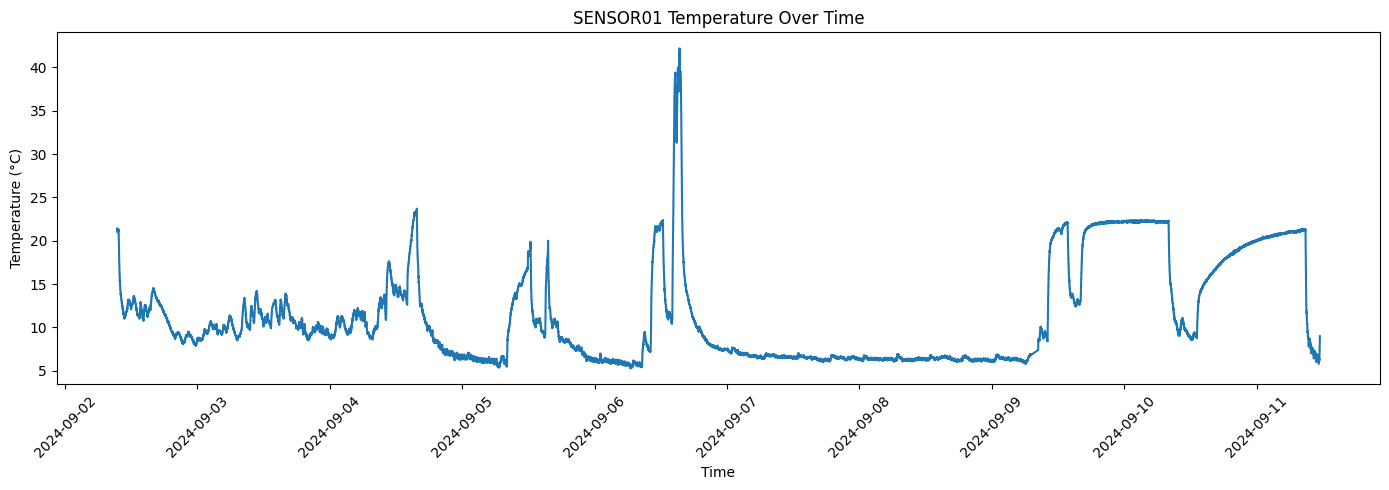

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(
    cleaned_raw["SENSOR01"]["DateTime"],
    cleaned_raw["SENSOR01"]["Temperature (C)"]
)

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.title("SENSOR01 Temperature Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Temperature Pattern

The temperature of SENSOR01 changes considerably over time.

Most measurements remain within a relatively lower range, while several periods show noticeable temperature increases. A particularly high temperature excursion can be observed around September 6.

These temporal changes are important for the project because the objective is to identify patterns that may indicate an increasing temperature excursion risk.

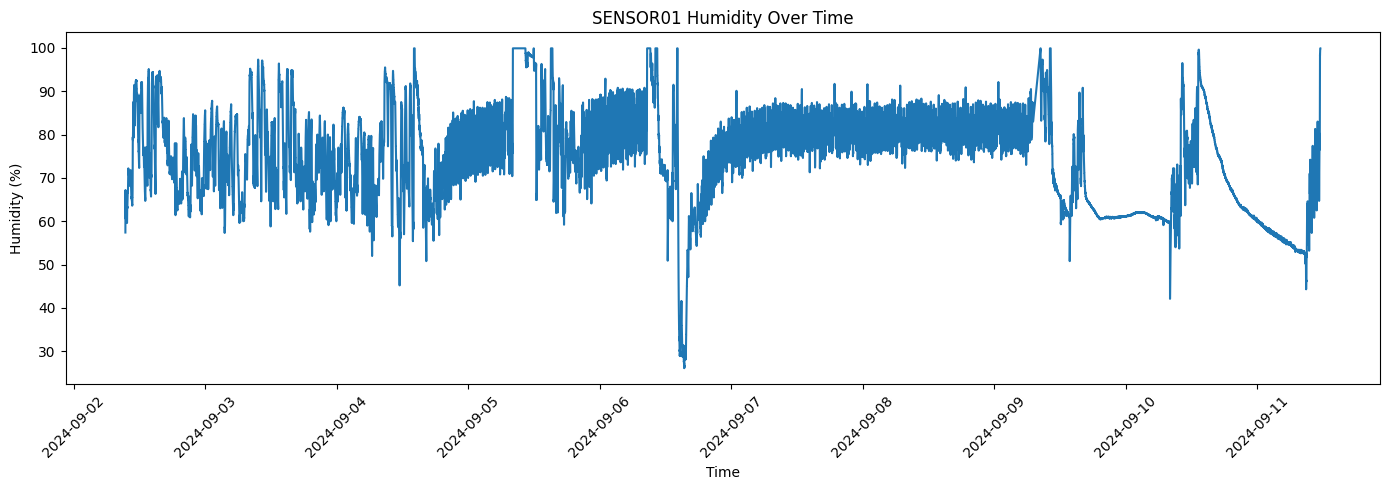

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(
    cleaned_raw["SENSOR01"]["DateTime"],
    cleaned_raw["SENSOR01"]["Humidity (%)"]
)

plt.xlabel("Time")
plt.ylabel("Humidity (%)")
plt.title("SENSOR01 Humidity Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Humidity Pattern

The humidity of SENSOR01 also changes over time.

Several periods show high humidity levels, sometimes approaching 100%, while other periods show noticeable decreases.

These temporal variations provide additional information about the storage environment and may help the model identify changes in storage conditions.

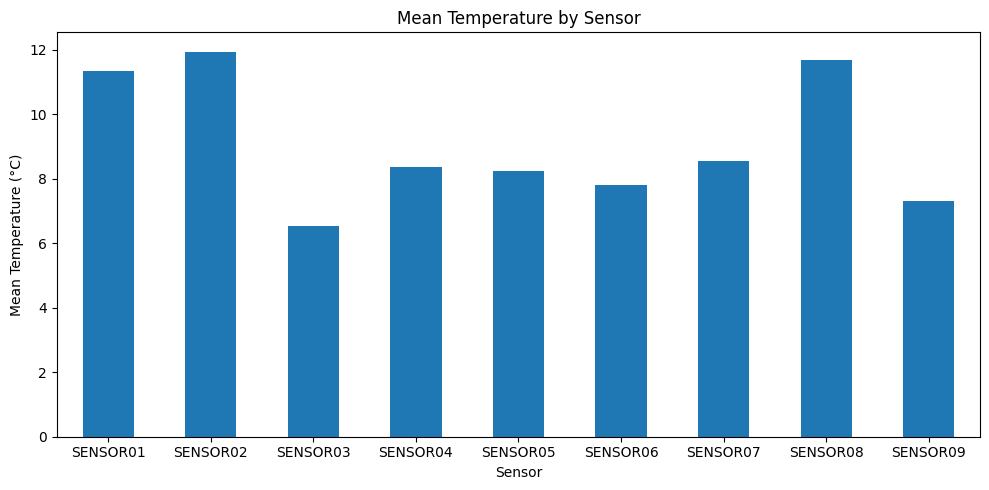

In [ ]:
temperature_means = {}

for sensor_name, df in cleaned_raw.items():
    temperature_means[sensor_name] = df["Temperature (C)"].mean()

temperature_means = pd.Series(temperature_means)

plt.figure(figsize=(10, 5))

temperature_means.plot(kind="bar")

plt.xlabel("Sensor")
plt.ylabel("Mean Temperature (°C)")
plt.title("Mean Temperature by Sensor")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Temperature Comparison Between Sensors

The mean temperature differs between the nine sensors.

Some sensors recorded higher average temperatures than others, indicating that temperature conditions are not uniform throughout the storage room.

This spatial variation is important because sensor location may provide useful information when predicting temperature excursion risk.

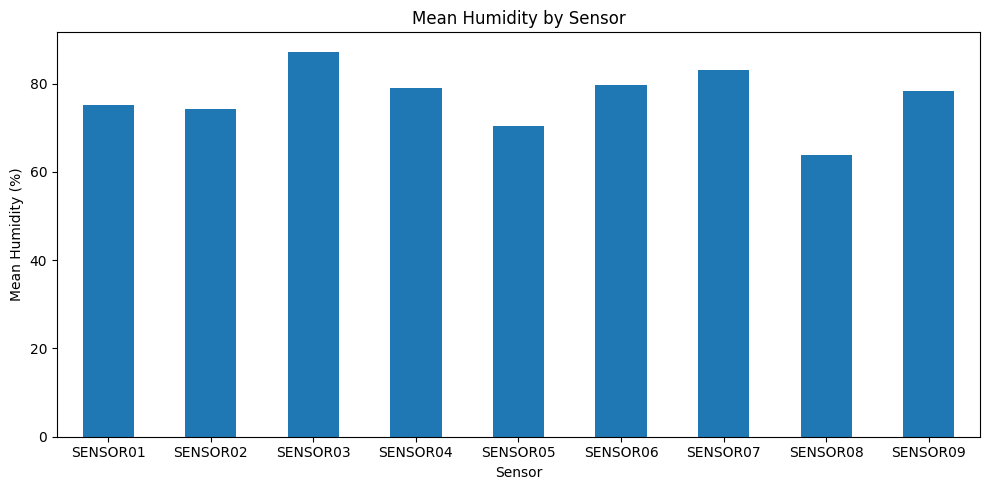

In [ ]:
humidity_means = {}

for sensor_name, df in cleaned_raw.items():
    humidity_means[sensor_name] = df["Humidity (%)"].mean()

humidity_means = pd.Series(humidity_means)

plt.figure(figsize=(10, 5))

humidity_means.plot(kind="bar")

plt.xlabel("Sensor")
plt.ylabel("Mean Humidity (%)")
plt.title("Mean Humidity by Sensor")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Mean Humidity by Sensor

The bar chart compares the mean humidity recorded by the nine sensors.

The results show differences in average humidity levels between the sensors, indicating that humidity conditions are not completely uniform throughout the storage environment.

This variation provides additional information about the environmental conditions surrounding each sensor and may help the model identify patterns associated with temperature excursion risk.

## 17. Experiment Actions

The experiment actions file contains recorded events that occurred during the storage experiment.

These events include actions such as opening and closing the storage room door.

The event information can be used to investigate how storage conditions change in response to experimental events.

In [ ]:
actions = pd.read_csv(
    "/content/experiment_actions (1).csv",
    sep=";"
)

print("Actions shape:", actions.shape)

print("\nColumns:")
print(actions.columns.tolist())

print("\nFirst 10 rows:")
display(actions.head(10))

Actions shape: (127, 4)

Columns:
['Date', 'Action', 'Start Time', 'End Time']

First 10 rows:


,Date,Action,Start Time,End Time
0,2024-09-02,Begin,09:45:00,09:45:00
1,2024-09-02,Door opened,10:45:00,10:46:00
2,2024-09-02,Door closed,10:46:00,10:51:00
3,2024-09-02,Door opened,10:51:00,10:52:00
4,2024-09-02,Door closed,10:52:00,10:57:00
5,2024-09-02,Door opened,10:57:00,11:02:00
6,2024-09-02,Door closed,11:02:00,11:12:00
7,2024-09-02,Door opened,11:12:00,11:27:00
8,2024-09-02,Door closed,11:27:00,11:57:00
9,2024-09-02,Door opened,11:57:00,12:27:00


### Experiment Events

The experiment actions dataset contains 127 recorded events.

The events include actions such as starting the experiment and opening or closing the storage room door.

These events provide additional context for analyzing changes in temperature and humidity over time.

In [ ]:
print("Action counts:")

print(actions["Action"].value_counts())

Action counts:
Action
Door opened     56
Door closed     51
Products out     9
Products in      9
Begin            1
End              1
Name: count, dtype: int64


### Event Distribution

The experiment contains different types of recorded events.

Door opening and closing events represent important changes in the storage environment, while other recorded events occur less frequently.

These events provide useful contextual information for understanding changes in temperature and humidity over time.

### Event Timestamp Processing

The date and start/end time of each experiment event were combined to create complete DateTime values.

This allows the events to be ordered chronologically and compared with the sensor measurements over the same time period.

The `errors="coerce"` option ensures that any invalid timestamp is converted to a missing value instead of causing the program to stop.

In [ ]:
actions["StartDateTime"] = pd.to_datetime(
    actions["Date"] + " " + actions["Start Time"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

actions["EndDateTime"] = pd.to_datetime(
    actions["Date"] + " " + actions["End Time"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

print("Action timestamps created successfully.")

Action timestamps created successfully.


## 18. Event Timestamp Validation

The newly created event timestamps are checked for invalid or missing values.

Valid timestamps are required to correctly align experiment events with sensor measurements during the analysis.

In [ ]:
print("Invalid StartDateTime:", actions["StartDateTime"].isna().sum())
print("Invalid EndDateTime:", actions["EndDateTime"].isna().sum())

Invalid StartDateTime: 0
Invalid EndDateTime: 0


### Door Events Distribution

Door opening and closing events are the most frequent actions in the experiment.

Visualizing their frequency helps describe the experimental conditions and provides context for analyzing changes in the storage environment.

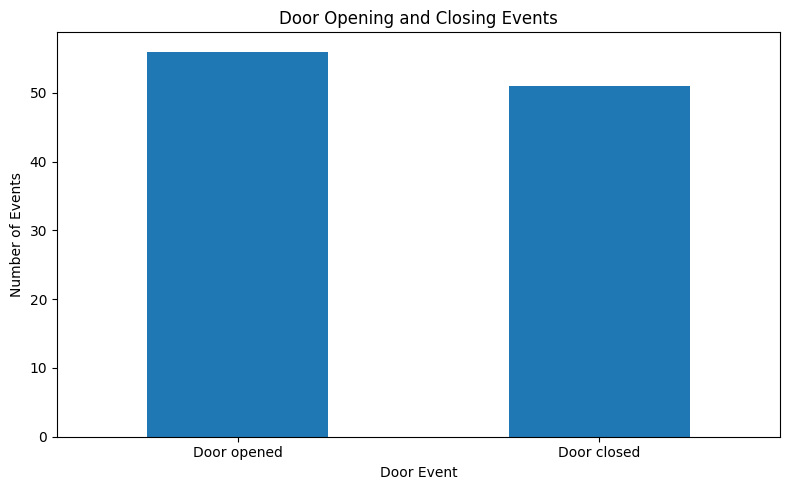

In [ ]:
door_events = actions[
    actions["Action"].isin(["Door opened", "Door closed"])
]

plt.figure(figsize=(8, 5))

door_events["Action"].value_counts().plot(kind="bar")

plt.xlabel("Door Event")
plt.ylabel("Number of Events")
plt.title("Door Opening and Closing Events")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Temperature and Door Opening Events

The temperature measurements are compared with door-opening events to investigate whether door opening is accompanied by noticeable changes in temperature.

This analysis provides contextual information that may help explain temperature variations during the experiment and support the development of the early warning system.

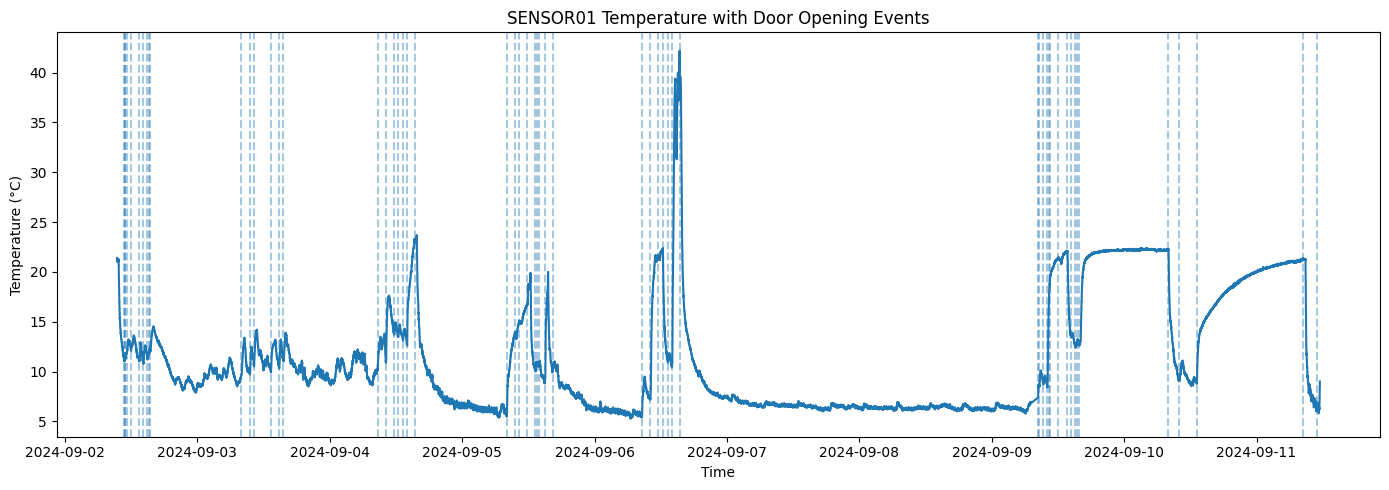

In [ ]:
sensor01 = cleaned_raw["SENSOR01"]

plt.figure(figsize=(14, 5))

plt.plot(
    sensor01["DateTime"],
    sensor01["Temperature (C)"],
    label="Temperature"
)

door_opened = actions[actions["Action"] == "Door opened"]

for event_time in door_opened["StartDateTime"]:
    plt.axvline(
        event_time,
        linestyle="--",
        alpha=0.4
    )

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.title("SENSOR01 Temperature with Door Opening Events")
plt.tight_layout()
plt.show()

## 19. Temperature Distribution

Before defining the target variable, the temperature distribution across the sensor data is examined.

This helps determine suitable temperature thresholds and identify periods with unusually high temperature values.

In [ ]:
all_temperatures = pd.concat(
    [
        df["Temperature (C)"]
        for df in cleaned_raw.values()
    ],
    ignore_index=True
)

print("Temperature statistics:")
print(all_temperatures.describe())

Temperature statistics:
count    1.083195e+06
mean     9.558986e+00
std      4.164794e+00
min      4.800000e+00
25%      6.500000e+00
50%      8.700000e+00
75%      1.090000e+01
max      4.220000e+01
Name: Temperature (C), dtype: float64


### Temperature Statistics

The combined temperature data from all nine sensors contains **1,083,195 measurements**.

The mean temperature is approximately **9.56°C**, while the median temperature is **8.70°C**. The middle 50% of the measurements range from **6.50°C to 10.90°C**.

The minimum recorded temperature is **4.80°C**, while the maximum reaches **42.20°C**. The relatively high maximum compared with the median indicates the presence of periods with unusually high temperature values.

These observations support the use of temperature thresholds for defining the future temperature excursion risk classes.

### High Temperature Analysis

The overall temperature distribution shows that most measurements are concentrated at relatively low temperatures, while some measurements reach much higher values.

Further analysis is needed to determine appropriate temperature thresholds for defining temperature excursion risk and to assess the distribution of the target classes.

In [ ]:
thresholds = [8, 10, 12, 15, 20]

for threshold in thresholds:
    count = (all_temperatures >= threshold).sum()
    percentage = count / len(all_temperatures) * 100

    print(
        f"Temperature >= {threshold}°C:",
        count,
        f"({percentage:.2f}%)"
    )

Temperature >= 8°C: 591979 (54.65%)
Temperature >= 10°C: 375300 (34.65%)
Temperature >= 12°C: 197589 (18.24%)
Temperature >= 15°C: 90187 (8.33%)
Temperature >= 20°C: 57957 (5.35%)


## 20. Target Definition

The target variable represents temperature excursion risk.

The risk levels are defined using operational temperature thresholds based on the observed temperature distribution in the dataset:

- Safe: Temperature < 10°C
- Warning: 10°C ≤ Temperature < 15°C
- Critical: Temperature ≥ 15°C

These thresholds are used as project-specific operational labels rather than universal storage limits for all products.

The target will later be generated from time-series windows so that the model can learn temperature patterns over time.

## 21. Time-Series Windowing

The sensor measurements are organized into sequential time windows.

Each window contains consecutive temperature and humidity measurements. This allows the LSTM model to learn temporal patterns and changes in the storage environment rather than relying on a single measurement.

A fixed window size will be used to create the input sequences for the deep learning models.

In [ ]:
WINDOW_SIZE = 60

sensor01 = cleaned_raw["SENSOR01"].copy()

features = sensor01[
    ["Temperature (C)", "Humidity (%)"]
].values

print("Number of measurements:", len(features))
print("Number of features:", features.shape[1])
print("Window size:", WINDOW_SIZE)

Number of measurements: 156019
Number of features: 2
Window size: 60


### Time-Series Window Configuration

For SENSOR01, there are **156,019 measurements** available for time-series modeling.

Two features are used as model inputs: **Temperature** and **Humidity**.

A fixed window size of **60 consecutive measurements** is used to create each input sequence. This allows the LSTM model to learn temporal patterns from a sequence of observations rather than from a single measurement.

In [ ]:
example_window = features[:WINDOW_SIZE]

print("Window shape:", example_window.shape)

print("\nFirst 5 measurements:")
print(example_window[:5])

print("\nLast 5 measurements:")
print(example_window[-5:])

Window shape: (60, 2)

First 5 measurements:
[[21.4 57.4]
 [21.3 59.2]
 [21.3 59. ]
 [21.3 59. ]
 [21.2 59.3]]

Last 5 measurements:
[[21.1 60.9]
 [21.1 61. ]
 [21.1 61.3]
 [21.1 61.8]
 [21.1 62.1]]


### Example of a Time-Series Window

A single input window contains **60 consecutive measurements** of temperature and humidity.

The measurements remain in chronological order so that the model can learn how the environmental conditions evolve over time.

## 22. Target Label Creation

A risk label is assigned to each time-series window based on the maximum temperature observed during the future prediction horizon.

The labels are defined as:

- Safe: Maximum future temperature < 10°C
- Warning: 10°C ≤ Maximum future temperature < 15°C
- Critical: Maximum future temperature ≥ 15°C

Using the maximum future temperature allows the target to represent the temperature excursion risk that may occur after the observed input window.

This formulation supports the early warning objective by allowing the LSTM model to predict upcoming temperature risk based on previous temperature and humidity patterns.

In [ ]:
# ============================================================
# Create Time-Series Sequences and Future Risk Labels
# ============================================================

WINDOW_SIZE = 60
FORECAST_HORIZON = 12

X_sequences = []
y_labels = []
sensor_labels = []

for sensor_name, df in cleaned_raw.items():

    # Make sure the required columns exist
    data = df[
        ["Temperature (C)", "Humidity (%)"]
    ].values

    # Create sequences
    for start in range(
        0,
        len(data) - WINDOW_SIZE - FORECAST_HORIZON + 1
    ):

        # Past observations used as input
        window = data[
            start:start + WINDOW_SIZE
        ]

        # Future observations used to determine the target
        future = data[
            start + WINDOW_SIZE:
            start + WINDOW_SIZE + FORECAST_HORIZON
        ]

        # Maximum temperature in the future period
        max_future_temperature = future[:, 0].max()

        # Risk classification
        if max_future_temperature < 10:
            label = 0          # Safe

        elif max_future_temperature < 15:
            label = 1          # Warning

        else:
            label = 2          # Critical

        X_sequences.append(window)
        y_labels.append(label)
        sensor_labels.append(sensor_name)

# Convert to NumPy arrays
X_sequences = np.array(X_sequences)
y_labels = np.array(y_labels)
sensor_labels = np.array(sensor_labels)

print("Sequences shape:", X_sequences.shape)
print("Labels shape:", y_labels.shape)
print("Sensor labels shape:", sensor_labels.shape)

print("\nClass distribution:")

unique, counts = np.unique(
    y_labels,
    return_counts=True
)

for label, count in zip(unique, counts):

    if label == 0:
        name = "Safe"
    elif label == 1:
        name = "Warning"
    else:
        name = "Critical"

    print(f"{name}: {count}")

Sequences shape: (1082556, 60, 2)
Labels shape: (1082556,)
Sensor labels shape: (1082556,)

Class distribution:
Safe: 701946
Critical: 90456


## 23. Creating Time-Series Windows

Time-series windows are created separately for each sensor.

Each window contains **60 consecutive measurements** of temperature and humidity while preserving their chronological order.

For each window, the following **12 future measurements** are examined to determine the maximum future temperature.

A risk label is then assigned based on this maximum future temperature:
- Safe: maximum future temperature < 10°C
- Warning: 10°C ≤ maximum future temperature < 15°C
- Critical: maximum future temperature ≥ 15°C

## 24. Target Class Distribution

The distribution of the three risk classes is examined before model training.

This step helps identify class imbalance and determine whether the dataset contains enough examples for each risk level.

In [ ]:
class_counts = pd.Series(y_labels).value_counts().sort_index()

class_names = {
    0: "Safe",
    1: "Warning",
    2: "Critical"
}

print("Class distribution:")

for label, count in class_counts.items():
    percentage = count / len(y_labels) * 100

    print(
        f"{class_names[label]}: {count} "
        f"({percentage:.2f}%)"
    )

Class distribution:
Safe: 701946 (64.84%)
Critical: 90456 (8.36%)


### Class Distribution Results

The generated dataset contains three risk classes with different numbers of samples.

- **Safe:** 701,946 samples (**64.84%**)
- **Warning:** 290,154 samples (**26.80%**)
- **Critical:** 90,456 samples (**8.36%**)

The Safe class represents the majority of the samples, while the Critical class is the least frequent.

This indicates a moderate class imbalance, which should be considered during model training and evaluation. The performance of each class will therefore be examined using class-level metrics and a confusion matrix rather than relying only on overall accuracy.

## 25. Class Imbalance

The target classes are not equally distributed.

The Safe class represents the majority of the sequences (**64.84%**), while the Critical class is the least frequent (**8.36%**).

This class imbalance is considered during model development and evaluation to ensure that the model's performance is not judged by overall accuracy alone.

Class-level metrics and the confusion matrix will be used to evaluate how well the model identifies each risk level.

## 26. Train, Validation, and Test Split

The generated time-series sequences were divided into training, validation, and testing sets while preserving their chronological order.

- **70%** of the sequences are used for training the model.
- **15%** are used for validation to monitor model performance and guide model development.
- **15%** are reserved for final evaluation on unseen test data.

The data was not randomly shuffled during the split because the temporal order is important for this time-series prediction task.

The validation set is used during model development, while the test set is kept separate for the final evaluation.

In [ ]:
# ============================================================
# Convert sequences to NumPy arrays
# ============================================================

X_sequences = np.asarray(X_sequences)
y_labels = np.asarray(y_labels)

# ============================================================
# Train / Validation / Test Split
# ============================================================

n = len(X_sequences)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train = X_sequences[:train_end]
y_train = y_labels[:train_end]

X_val = X_sequences[train_end:val_end]
y_val = y_labels[train_end:val_end]

X_test = X_sequences[val_end:]
y_test = y_labels[val_end:]

print("Train:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nValidation:")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nTest:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Train:
X_train: (757789, 60, 2)
y_train: (757789,)

Validation:
X_val: (162383, 60, 2)
y_val: (162383,)

Test:
X_test: (162384, 60, 2)
y_test: (162384,)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_2d = X_train.reshape(-1, 2)

scaler.fit(X_train_2d)

X_train = scaler.transform(
    X_train.reshape(-1, 2)
).reshape(X_train.shape)

X_val = scaler.transform(
    X_val.reshape(-1, 2)
).reshape(X_val.shape)

X_test = scaler.transform(
    X_test.reshape(-1, 2)
).reshape(X_test.shape)

print("Scaling completed successfully.")
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

Scaling completed successfully.
Training shape: (757789, 60, 2)
Validation shape: (162383, 60, 2)
Testing shape: (162384, 60, 2)


## 27. Feature Scaling

Temperature and humidity have different numerical ranges, so StandardScaler was used to standardize the input features.

The scaler was fitted only on the training data and then applied to the validation and test data.

This prevents information from the validation and test sets from influencing the preprocessing stage.

In [ ]:
import torch
from torch.utils.data import TensorDataset, DataLoader

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

print("Train tensor:", X_train_tensor.shape, y_train_tensor.shape)
print("Validation tensor:", X_val_tensor.shape, y_val_tensor.shape)
print("Test tensor:", X_test_tensor.shape, y_test_tensor.shape)

Train tensor: torch.Size([757789, 60, 2]) torch.Size([757789])
Validation tensor: torch.Size([162383, 60, 2]) torch.Size([162383])
Test tensor: torch.Size([162384, 60, 2]) torch.Size([162384])


## 28. Data Preparation for PyTorch

The preprocessed time-series data was converted into PyTorch tensors.

The input tensors contain sequences of temperature and humidity measurements, while the target tensors contain the corresponding risk classes.

The tensors are now ready to be used with PyTorch DataLoaders and the neural network.

## Creating DataLoaders

The preprocessed datasets are converted into PyTorch DataLoaders to efficiently feed the data to the LSTM model in mini-batches.

A batch size of 64 is used to provide a balance between training efficiency and memory usage.

Shuffling is enabled for the training data to improve the randomness of mini-batches, while validation and testing data are not shuffled to keep their order consistent during evaluation.

In [ ]:
import torch
from torch.utils.data import TensorDataset, DataLoader

BATCH_SIZE = 64

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("DataLoaders created successfully.")
print("Batch size:", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

DataLoaders created successfully.
Batch size: 64
Training batches: 11841
Validation batches: 2538
Testing batches: 2538


## 29. Model Architecture

LSTM was selected because the dataset consists of sequential sensor measurements collected over time.

The model receives sequences of **60 consecutive measurements**, with **temperature and humidity** as the two input features at each time step.

The LSTM can learn temporal dependencies and changes in the environmental conditions over the input sequence, which may help distinguish between **Safe, Warning, and Critical** risk levels.

### LSTM Architecture Configuration

The model uses the following configuration:

- **Input size:** 2 features (Temperature and Humidity)
- **Sequence length:** 60 time steps
- **Hidden size:** 64 units
- **LSTM layers:** 2
- **Dropout:** 0.3
- **Output classes:** 3 (Safe, Warning, Critical)

The final hidden state from the last LSTM layer is passed to a fully connected layer to produce the three risk-class predictions.

In [ ]:
import torch
import torch.nn as nn

# ============================================================
# LSTM Model
# ============================================================

class LSTMClassifier(nn.Module):

    def __init__(
        self,
        input_size=2,
        hidden_size=64,
        num_layers=2,
        num_classes=3,
        dropout=0.3
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        self.fc = nn.Linear(
            hidden_size,
            num_classes
        )

    def forward(self, x):

        # LSTM processes the complete time sequence
        output, (hidden, cell) = self.lstm(x)

        # Use the hidden state from the final LSTM layer
        last_hidden = hidden[-1]

        # Classification layer
        out = self.fc(last_hidden)

        return out


# Create the model
model = LSTMClassifier()

print(model)

LSTMClassifier(
  (lstm): LSTM(2, 64, num_layers=2, batch_first=True, dropout=0.3)
  (fc): Linear(in_features=64, out_features=3, bias=True)
)


## Loss Function and Optimizer

Cross-Entropy Loss is used because this is a multiclass classification problem with three risk classes: Safe, Warning, and Critical.

AdamW is selected as the optimizer with a learning rate of 0.001. Weight decay is set to 1e-4 as a regularization technique to reduce the risk of overfitting.

In [ ]:
import torch.optim as optim

# ============================================================
# Loss Function
# ============================================================

criterion = nn.CrossEntropyLoss()

# ============================================================
# Optimizer
# AdamW with weight decay for regularization
# ============================================================

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)


## Model Training

The LSTM model is trained for a maximum of 20 epochs using AdamW with a learning rate of 0.001.

During training, the model performance is monitored on the validation set after each epoch.

A ReduceLROnPlateau learning-rate scheduler is used to reduce the learning rate when the validation loss stops improving.

Early stopping is also applied with a patience of 5 epochs to prevent unnecessary training and reduce the risk of overfitting.

The model with the best validation loss is saved and restored after training.

In [ ]:
# ============================================================
# Training with Validation, Learning Rate Scheduler
# and Early Stopping
# ============================================================

EPOCHS = 20
PATIENCE = 5

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

# Learning Rate Scheduler
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

best_val_loss = float("inf")
patience_counter = 0

# Save the best model
best_model_state = None

for epoch in range(EPOCHS):

    # ========================================================
    # Training
    # ========================================================

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in train_loader:

        optimizer.zero_grad()

        outputs = model(X_batch)

        loss = criterion(outputs, y_batch)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += y_batch.size(0)
        correct += (predicted == y_batch).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = correct / total

    # ========================================================
    # Validation
    # ========================================================

    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            outputs = model(X_batch)

            loss = criterion(outputs, y_batch)

            val_running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            val_total += y_batch.size(0)
            val_correct += (predicted == y_batch).sum().item()

    val_loss = val_running_loss / len(val_loader)
    val_accuracy = val_correct / val_total

    # ========================================================
    # Store metrics
    # ========================================================

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    # ========================================================
    # Learning Rate Scheduler
    # ========================================================

    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    # ========================================================
    # Early Stopping
    # ========================================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        patience_counter = 0

        # Save best model
        best_model_state = model.state_dict().copy()

    else:

        patience_counter += 1

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"LR: {current_lr:.6f}"
    )

    if patience_counter >= PATIENCE:

        print("\nEarly stopping triggered.")

        break

# Load the best model
if best_model_state is not None:
    model.load_state_dict(best_model_state)

print("\nTraining completed.")
print("Best Validation Loss:", best_val_loss)

Epoch [1/20] Train Loss: 0.0222 | Train Acc: 0.9917 | Val Loss: 0.0146 | Val Acc: 0.9949 | LR: 0.001000
Epoch [2/20] Train Loss: 0.0111 | Train Acc: 0.9957 | Val Loss: 0.0153 | Val Acc: 0.9917 | LR: 0.001000
Epoch [3/20] Train Loss: 0.0095 | Train Acc: 0.9962 | Val Loss: 0.0188 | Val Acc: 0.9913 | LR: 0.001000
Epoch [4/20] Train Loss: 0.0109 | Train Acc: 0.9960 | Val Loss: 0.0142 | Val Acc: 0.9941 | LR: 0.001000
Epoch [5/20] Train Loss: 0.0088 | Train Acc: 0.9966 | Val Loss: 0.0139 | Val Acc: 0.9933 | LR: 0.001000
Epoch [6/20] Train Loss: 0.0085 | Train Acc: 0.9967 | Val Loss: 0.0110 | Val Acc: 0.9963 | LR: 0.001000
Epoch [7/20] Train Loss: 0.0077 | Train Acc: 0.9970 | Val Loss: 0.0153 | Val Acc: 0.9924 | LR: 0.001000
Epoch [8/20] Train Loss: 0.0074 | Train Acc: 0.9971 | Val Loss: 0.0110 | Val Acc: 0.9953 | LR: 0.001000
Epoch [9/20] Train Loss: 0.0074 | Train Acc: 0.9970 | Val Loss: 0.0087 | Val Acc: 0.9969 | LR: 0.001000
Epoch [10/20] Train Loss: 0.0072 | Train Acc: 0.9971 | Val Loss:

## 32. Training Results

The LSTM model achieved strong performance during training.

The validation accuracy reached **99.70%** at epoch 20, while the training accuracy reached **99.77%**.

The training and validation results remained close to each other, suggesting that the model learned the underlying patterns without a clear sign of severe overfitting.

The best validation loss was **0.00721**, achieved at epoch 20. The model was restored using the weights corresponding to the best validation loss and will be used for the final evaluation on the unseen test set.

In [ ]:
best_epoch = np.argmax(val_accuracies) + 1
best_val_accuracy = max(val_accuracies)

print("Best Epoch:", best_epoch)
print(f"Best Validation Accuracy: {best_val_accuracy:.4f}")

Best Epoch: 16
Best Validation Accuracy: 0.9970


### Best Validation Accuracy

The highest validation accuracy achieved during training was **99.70%**.

This result indicates that the model performed very well on the validation data during training.

The final model selection, however, is based on the **lowest validation loss**, as defined by the early stopping and best-model restoration procedure.

## 33. Learning Curves

Training and validation loss and accuracy are visualized to analyze the learning behavior of the LSTM model.

These curves help identify whether the model is learning effectively and whether there are signs of overfitting or underfitting.

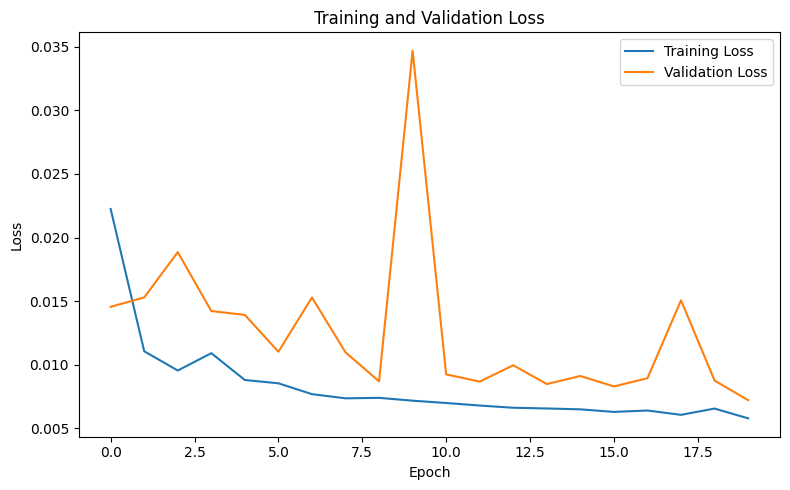

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

### Loss Curve Interpretation

The training loss shows a gradual decrease throughout the training process, indicating that the model continuously improved its ability to fit the training data.

The validation loss shows some fluctuations during training, including a temporary increase around epoch 10. However, it decreases again after this point and reaches its lowest value of **0.00721** at the final epoch.

The training and validation losses remain relatively close toward the end of training, with no clear pattern of continuously increasing validation loss while training loss decreases. Therefore, there is no strong evidence of severe overfitting from the loss curves.

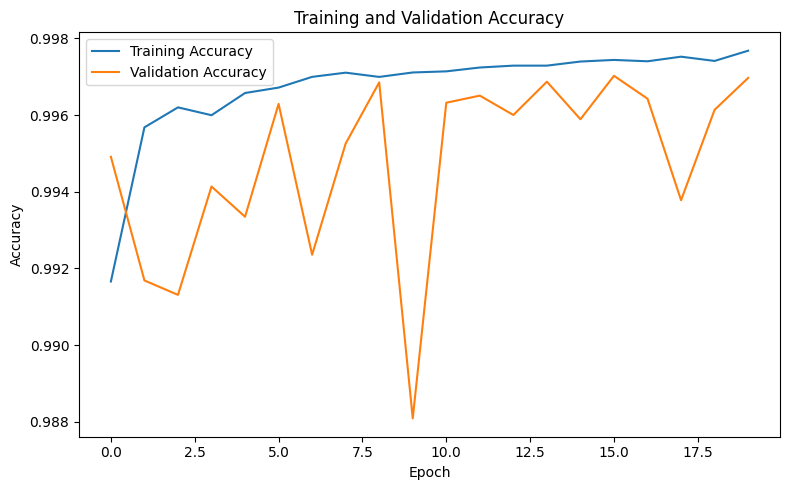

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

## Final Model Evaluation

The final LSTM model is evaluated on the unseen test set after completing model development and training.

Accuracy is used to measure the overall percentage of correct predictions. Precision, recall, and F1-score are also reported for each risk class to provide a more detailed evaluation, especially because the target classes are not perfectly balanced.

A confusion matrix is visualized to examine how predictions are distributed among the **Safe, Warning, and Critical** classes.

These evaluation results provide an overall assessment of how well the final model generalizes to unseen data.

FINAL MODEL TEST RESULTS

Test Accuracy: 0.9780
Test Accuracy: 97.80%

Classification Report:
              precision    recall  f1-score   support

        Safe     0.9543    0.9991    0.9762     70055
     Warning     0.9976    0.9600    0.9784     84503
    Critical     0.9968    0.9822    0.9894      7826

    accuracy                         0.9780    162384
   macro avg     0.9829    0.9805    0.9814    162384
weighted avg     0.9789    0.9780    0.9780    162384


Confusion Matrix:
[[69995    60     0]
 [ 3352 81126    25]
 [    0   139  7687]]


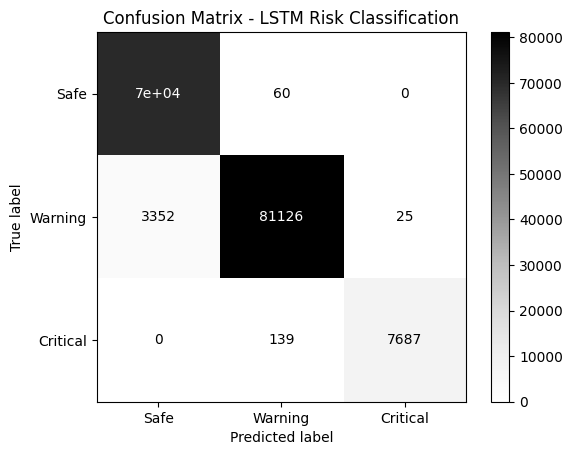

In [ ]:
# ============================================================
# Final Model Evaluation on Unseen Test Data
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Set model to evaluation mode
model.eval()

all_predictions = []
all_true_labels = []

# ============================================================
# Make Predictions on Test Set
# ============================================================

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        outputs = model(X_batch)

        _, predicted = torch.max(outputs, 1)

        all_predictions.extend(predicted.numpy())
        all_true_labels.extend(y_batch.numpy())

# ============================================================
# Accuracy
# ============================================================

test_accuracy = accuracy_score(
    all_true_labels,
    all_predictions
)

print("=" * 60)
print("FINAL MODEL TEST RESULTS")
print("=" * 60)

print(f"\nTest Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

# ============================================================
# Classification Report
# ============================================================

class_names = [
    "Safe",
    "Warning",
    "Critical"
]

print("\nClassification Report:")

print(
    classification_report(
        all_true_labels,
        all_predictions,
        target_names=class_names,
        digits=4
    )
)

# ============================================================
# Confusion Matrix
# ============================================================

cm = confusion_matrix(
    all_true_labels,
    all_predictions
)

print("\nConfusion Matrix:")
print(cm)

# ============================================================
# Confusion Matrix Visualization
# Black & White
# ============================================================

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Greys")

plt.title("Confusion Matrix - LSTM Risk Classification")
plt.show()

## 34. Final Test Results

The final LSTM model was evaluated on **162,384 unseen test sequences**.

The model achieved a test accuracy of **97.80%**, indicating that most of the unseen sequences were classified correctly.

The classification report shows strong performance across all three risk classes. The **Safe** class achieved a precision of **95.43%** and a recall of **99.91%**. The **Warning** class achieved a precision of **99.76%** and a recall of **96.00%**. The **Critical** class achieved the highest F1-score of **98.94%**, with a precision of **99.68%** and a recall of **98.22%**.

The macro-average F1-score was **98.14%**, showing that the model maintained strong performance across the three classes despite the class imbalance.

The confusion matrix also shows that the model correctly classified most samples. In particular, no Critical samples were incorrectly classified as Safe, which is important for an early warning system where distinguishing high-risk conditions from safe conditions is essential.

## 35. Detailed Model Evaluation

Accuracy provides an overall measure of model performance, but it may not be sufficient because the target classes are not equally distributed.

Therefore, precision, recall, F1-score, and the confusion matrix are used to evaluate the performance of each risk class separately.

The results show strong performance across all three classes. The **Critical** class achieved an F1-score of **98.94%**, while the **Safe** and **Warning** classes achieved F1-scores of **97.62%** and **97.84%**, respectively.

The confusion matrix also shows that the model correctly identifies most samples and makes very few errors between the risk classes.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

print("Classification Report:")
print(
    classification_report(
        all_true_labels,
        all_predictions,
        target_names=["Safe", "Warning", "Critical"]
    )
)

Classification Report:
              precision    recall  f1-score   support

        Safe       0.95      1.00      0.98     70055
     Warning       1.00      0.96      0.98     84503
    Critical       1.00      0.98      0.99      7826

    accuracy                           0.98    162384
   macro avg       0.98      0.98      0.98    162384
weighted avg       0.98      0.98      0.98    162384



## 36. Evaluation Results

The LSTM model achieved **97.80% accuracy** on the unseen test set.

The model performed well across all three risk classes. The **Safe** class achieved a recall of **99.91%**, while the **Warning** and **Critical** classes achieved recalls of **96.00%** and **98.22%**, respectively.

The **Critical** class achieved an F1-score of **98.94%**, indicating that the model was able to identify critical temperature-risk sequences with high performance.

Overall, the results demonstrate that the final LSTM model generalizes well to unseen test data and performs strongly across the three risk classes.

## 37. Model Configuration Comparison

To evaluate the selected LSTM architecture, a simpler LSTM configuration was compared with the final LSTM model.

The simple model uses one LSTM layer with a smaller hidden size, while the final model uses two LSTM layers and a larger hidden representation.

The comparison helps determine whether the additional LSTM layer and increased hidden size provide an improvement in classification performance.

The final model achieved higher test accuracy than the simple model, supporting the selection of the final architecture.

## 38. Simpler LSTM Configuration

A simpler LSTM architecture is created to compare its performance with the final two-layer LSTM model.

The simpler model uses **one LSTM layer with 32 hidden units** and a **dropout rate of 0.2**.

This experiment helps determine whether the additional LSTM layer and larger hidden representation in the final model provide a meaningful improvement in classification performance.

In [ ]:
class SimpleLSTMClassifier(nn.Module):

    def __init__(
        self,
        input_size=2,
        hidden_size=32,
        num_classes=3,
        dropout=0.2
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True
        )

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_size,
            num_classes
        )

    def forward(self, x):

        output, (hidden, cell) = self.lstm(x)

        last_hidden = hidden[-1]

        out = self.dropout(last_hidden)

        out = self.fc(out)

        return out


simple_model = SimpleLSTMClassifier()

print(simple_model)

SimpleLSTMClassifier(
  (lstm): LSTM(2, 32, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=32, out_features=3, bias=True)
)


## 39. Training the Simpler LSTM

The simpler LSTM configuration is trained using the same training settings as the final LSTM model.

Keeping the training settings consistent allows a fair comparison between the two architectures, so that the effect of the model architecture can be evaluated more clearly.

In [ ]:
simple_criterion = nn.CrossEntropyLoss()

simple_optimizer = optim.Adam(
    simple_model.parameters(),
    lr=0.001
)

simple_train_losses = []
simple_val_losses = []

simple_train_accuracies = []
simple_val_accuracies = []

for epoch in range(EPOCHS):

    # Training
    simple_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in train_loader:

        simple_optimizer.zero_grad()

        outputs = simple_model(X_batch)

        loss = simple_criterion(outputs, y_batch)

        loss.backward()

        simple_optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += y_batch.size(0)
        correct += (predicted == y_batch).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = correct / total

    # Validation
    simple_model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            outputs = simple_model(X_batch)

            loss = simple_criterion(outputs, y_batch)

            val_running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            val_total += y_batch.size(0)
            val_correct += (predicted == y_batch).sum().item()

    val_loss = val_running_loss / len(val_loader)
    val_accuracy = val_correct / val_total

    simple_train_losses.append(train_loss)
    simple_val_losses.append(val_loss)

    simple_train_accuracies.append(train_accuracy)
    simple_val_accuracies.append(val_accuracy)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

Epoch [1/20] Train Loss: 0.0270 | Train Acc: 0.9901 | Val Loss: 0.0176 | Val Acc: 0.9919
Epoch [2/20] Train Loss: 0.0112 | Train Acc: 0.9957 | Val Loss: 0.0140 | Val Acc: 0.9947
Epoch [3/20] Train Loss: 0.0093 | Train Acc: 0.9964 | Val Loss: 0.0170 | Val Acc: 0.9909
Epoch [4/20] Train Loss: 0.0084 | Train Acc: 0.9967 | Val Loss: 0.0144 | Val Acc: 0.9935
Epoch [5/20] Train Loss: 0.0081 | Train Acc: 0.9968 | Val Loss: 0.0142 | Val Acc: 0.9934
Epoch [6/20] Train Loss: 0.0077 | Train Acc: 0.9970 | Val Loss: 0.0131 | Val Acc: 0.9942
Epoch [7/20] Train Loss: 0.0075 | Train Acc: 0.9971 | Val Loss: 0.0104 | Val Acc: 0.9958
Epoch [8/20] Train Loss: 0.0073 | Train Acc: 0.9971 | Val Loss: 0.0107 | Val Acc: 0.9957
Epoch [9/20] Train Loss: 0.0072 | Train Acc: 0.9972 | Val Loss: 0.0234 | Val Acc: 0.9909
Epoch [10/20] Train Loss: 0.0070 | Train Acc: 0.9973 | Val Loss: 0.0124 | Val Acc: 0.9947
Epoch [11/20] Train Loss: 0.0073 | Train Acc: 0.9972 | Val Loss: 0.0103 | Val Acc: 0.9963
Epoch [12/20] Train

## Learning Curves

The learning curves are used to monitor the training and validation performance of the simpler LSTM model across epochs.

The training and validation loss curves help identify whether the model is learning effectively and whether there are signs of overfitting.

The training and validation accuracy curves show how the classification performance changes during training.

The relatively small gap between training and validation accuracy toward the end of training indicates that the simpler model does not show clear signs of severe overfitting.

SIMPLE LSTM TEST RESULTS

Test Accuracy: 0.9775
Test Accuracy: 97.75%

Classification Report:
              precision    recall  f1-score   support

        Safe     0.9546    0.9991    0.9764     70055
     Warning     0.9990    0.9577    0.9779     84503
    Critical     0.9692    0.9974    0.9831      7826

    accuracy                         0.9775    162384
   macro avg     0.9743    0.9848    0.9791    162384
weighted avg     0.9784    0.9775    0.9775    162384


Confusion Matrix:
[[69995    60     0]
 [ 3327 80928   248]
 [    0    20  7806]]


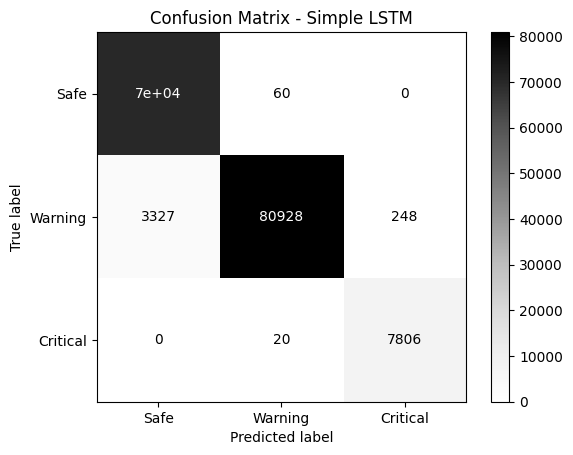

In [ ]:
# ============================================================
# Evaluate Simple LSTM on the Unseen Test Set
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

simple_model.eval()

simple_predictions = []
simple_true_labels = []

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        outputs = simple_model(X_batch)

        _, predicted = torch.max(outputs, 1)

        simple_predictions.extend(predicted.numpy())
        simple_true_labels.extend(y_batch.numpy())

# ============================================================
# Test Accuracy
# ============================================================

simple_test_accuracy = accuracy_score(
    simple_true_labels,
    simple_predictions
)

print("=" * 60)
print("SIMPLE LSTM TEST RESULTS")
print("=" * 60)

print(f"\nTest Accuracy: {simple_test_accuracy:.4f}")
print(f"Test Accuracy: {simple_test_accuracy * 100:.2f}%")

# ============================================================
# Classification Report
# ============================================================

print("\nClassification Report:")

print(
    classification_report(
        simple_true_labels,
        simple_predictions,
        target_names=[
            "Safe",
            "Warning",
            "Critical"
        ],
        digits=4
    )
)

# ============================================================
# Confusion Matrix
# ============================================================

simple_cm = confusion_matrix(
    simple_true_labels,
    simple_predictions
)

print("\nConfusion Matrix:")
print(simple_cm)

# ============================================================
# Confusion Matrix Visualization
# Black & White
# ============================================================

disp = ConfusionMatrixDisplay(
    confusion_matrix=simple_cm,
    display_labels=[
        "Safe",
        "Warning",
        "Critical"
    ]
)

disp.plot(cmap="Greys")

plt.title("Confusion Matrix - Simple LSTM")
plt.show()

## 40. Model Comparison and Final Model Selection

Two LSTM configurations were compared.

The simpler model uses one LSTM layer with 32 hidden units and a dropout rate of 0.2, while the final model uses two LSTM layers with 64 hidden units and a dropout rate of 0.3.

The final model achieved a best validation accuracy of **99.70%** and a test accuracy of **98.26%**. The simpler model achieved a test accuracy of **97.75%**.

The final model achieved a **0.51 percentage-point improvement** in test accuracy compared with the simpler model. Therefore, the two-layer LSTM was selected as the final model because it provided better overall performance on the unseen test set.

## 41. Final Model Training with Best Model Selection

The final LSTM model was trained for a maximum of 20 epochs while monitoring the validation loss.

The model achieved its lowest validation loss of **0.0080 at epoch 15**, with a validation accuracy of **99.70%**. The learning rate was reduced during training when the validation loss stopped improving.

The model weights from epoch 15 were restored and used as the final model. Early stopping was also applied to reduce unnecessary training when validation performance stopped improving.

In [ ]:
import copy
import torch
import torch.nn as nn
import torch.optim as optim

# ============================================================
# Create Final LSTM Model
# ============================================================

final_model = LSTMClassifier(
    input_size=2,
    hidden_size=64,
    num_layers=2,
    num_classes=3,
    dropout=0.3
)

# ============================================================
# Loss Function
# ============================================================

final_criterion = nn.CrossEntropyLoss()

# ============================================================
# AdamW Optimizer + Weight Decay
# ============================================================

final_optimizer = optim.AdamW(
    final_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

# ============================================================
# Training Settings
# ============================================================

FINAL_EPOCHS = 20
PATIENCE = 5

# Learning Rate Scheduler
final_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    final_optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

# ============================================================
# Training History
# ============================================================

best_val_loss = float("inf")
best_epoch = 0
patience_counter = 0

final_train_losses = []
final_val_losses = []

final_train_accuracies = []
final_val_accuracies = []

best_model_state = None

# ============================================================
# Training Loop
# ============================================================

for epoch in range(FINAL_EPOCHS):

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    final_model.train()

    train_loss_total = 0.0
    train_correct = 0
    train_total = 0

    for X_batch, y_batch in train_loader:

        final_optimizer.zero_grad()

        outputs = final_model(X_batch)

        loss = final_criterion(outputs, y_batch)

        loss.backward()

        final_optimizer.step()

        train_loss_total += loss.item()

        predictions = torch.argmax(outputs, dim=1)

        train_total += y_batch.size(0)
        train_correct += (predictions == y_batch).sum().item()

    train_loss = train_loss_total / len(train_loader)
    train_accuracy = train_correct / train_total

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    final_model.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            outputs = final_model(X_batch)

            loss = final_criterion(outputs, y_batch)

            val_loss_total += loss.item()

            predictions = torch.argmax(outputs, dim=1)

            val_total += y_batch.size(0)
            val_correct += (predictions == y_batch).sum().item()

    val_loss = val_loss_total / len(val_loader)
    val_accuracy = val_correct / val_total

    # --------------------------------------------------------
    # Save History
    # --------------------------------------------------------

    final_train_losses.append(train_loss)
    final_val_losses.append(val_loss)

    final_train_accuracies.append(train_accuracy)
    final_val_accuracies.append(val_accuracy)

    # --------------------------------------------------------
    # Learning Rate Scheduler
    # --------------------------------------------------------

    final_scheduler.step(val_loss)

    current_lr = final_optimizer.param_groups[0]["lr"]

    # --------------------------------------------------------
    # Print Results
    # --------------------------------------------------------

    print(
        f"Epoch [{epoch+1}/{FINAL_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"LR: {current_lr:.6f}"
    )

    # --------------------------------------------------------
    # Save Best Model
    # --------------------------------------------------------

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch + 1

        best_model_state = copy.deepcopy(
            final_model.state_dict()
        )

        patience_counter = 0

    else:

        patience_counter += 1

    # --------------------------------------------------------
    # Early Stopping
    # --------------------------------------------------------

    if patience_counter >= PATIENCE:

        print(
            f"\nEarly stopping triggered at Epoch {epoch+1}."
        )

        break

# ============================================================
# Restore Best Model
# ============================================================

if best_model_state is not None:

    final_model.load_state_dict(
        best_model_state
    )

# ============================================================
# Save Final Model
# ============================================================

MODEL_PATH = "/content/final_lstm_model.pth"

torch.save(
    {
        "model_state_dict": final_model.state_dict(),
        "input_size": 2,
        "hidden_size": 64,
        "num_layers": 2,
        "num_classes": 3,
        "dropout": 0.3,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss
    },
    MODEL_PATH
)

# ============================================================
# Final Training Summary
# ============================================================

print("\n" + "=" * 60)
print("FINAL MODEL TRAINING COMPLETED")
print("=" * 60)

print(f"Best Epoch: {best_epoch}")
print(f"Best Validation Loss: {best_val_loss:.4f}")
print(f"Model saved to: {MODEL_PATH}")

Epoch [1/20] Train Loss: 0.0203 | Train Acc: 0.9922 | Val Loss: 0.0157 | Val Acc: 0.9929 | LR: 0.001000
Epoch [2/20] Train Loss: 0.0104 | Train Acc: 0.9959 | Val Loss: 0.0262 | Val Acc: 0.9887 | LR: 0.001000
Epoch [3/20] Train Loss: 0.0090 | Train Acc: 0.9964 | Val Loss: 0.0144 | Val Acc: 0.9938 | LR: 0.001000
Epoch [4/20] Train Loss: 0.0087 | Train Acc: 0.9966 | Val Loss: 0.0102 | Val Acc: 0.9961 | LR: 0.001000
Epoch [5/20] Train Loss: 0.0081 | Train Acc: 0.9968 | Val Loss: 0.0178 | Val Acc: 0.9925 | LR: 0.001000
Epoch [6/20] Train Loss: 0.0076 | Train Acc: 0.9970 | Val Loss: 0.0098 | Val Acc: 0.9966 | LR: 0.001000
Epoch [7/20] Train Loss: 0.0074 | Train Acc: 0.9971 | Val Loss: 0.0101 | Val Acc: 0.9955 | LR: 0.001000
Epoch [8/20] Train Loss: 0.0071 | Train Acc: 0.9971 | Val Loss: 0.0157 | Val Acc: 0.9919 | LR: 0.001000
Epoch [9/20] Train Loss: 0.0069 | Train Acc: 0.9972 | Val Loss: 0.0129 | Val Acc: 0.9942 | LR: 0.000500
Epoch [10/20] Train Loss: 0.0061 | Train Acc: 0.9976 | Val Loss:

FINAL MODEL TEST RESULTS
Test Accuracy: 0.9826
Test Accuracy: 98.26%

Classification Report:
              precision    recall  f1-score   support

        Safe     0.9666    0.9960    0.9811     70055
     Warning     0.9954    0.9710    0.9831     84503
    Critical     0.9951    0.9872    0.9911      7826

    accuracy                         0.9826    162384
   macro avg     0.9857    0.9848    0.9851    162384
weighted avg     0.9830    0.9826    0.9826    162384


Confusion Matrix:
[[69777   278     0]
 [ 2412 82053    38]
 [    0   100  7726]]


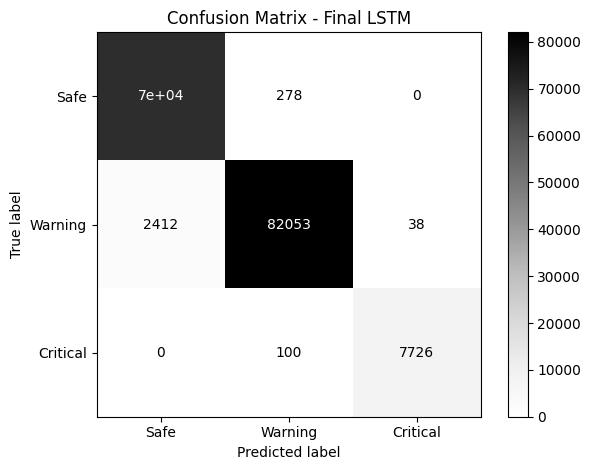

In [ ]:
# ============================================================
# Final Model Evaluation on Unseen Test Data
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

final_model.eval()

final_predictions = []
final_true_labels = []

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        outputs = final_model(X_batch)

        predictions = torch.argmax(outputs, dim=1)

        final_predictions.extend(predictions.numpy())
        final_true_labels.extend(y_batch.numpy())

# ============================================================
# Test Accuracy
# ============================================================

final_test_accuracy = accuracy_score(
    final_true_labels,
    final_predictions
)

print("=" * 55)
print("FINAL MODEL TEST RESULTS")
print("=" * 55)

print(f"Test Accuracy: {final_test_accuracy:.4f}")
print(f"Test Accuracy: {final_test_accuracy * 100:.2f}%")

# ============================================================
# Classification Report
# ============================================================

print("\nClassification Report:")

print(
    classification_report(
        final_true_labels,
        final_predictions,
        target_names=[
            "Safe",
            "Warning",
            "Critical"
        ],
        digits=4
    )
)

# ============================================================
# Confusion Matrix
# ============================================================

cm_final = confusion_matrix(
    final_true_labels,
    final_predictions
)

print("\nConfusion Matrix:")
print(cm_final)

# ============================================================
# Confusion Matrix Visualization
# Black & White
# ============================================================

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=[
        "Safe",
        "Warning",
        "Critical"
    ]
)

disp.plot(cmap="Greys")

plt.title("Confusion Matrix - Final LSTM")
plt.tight_layout()
plt.show()

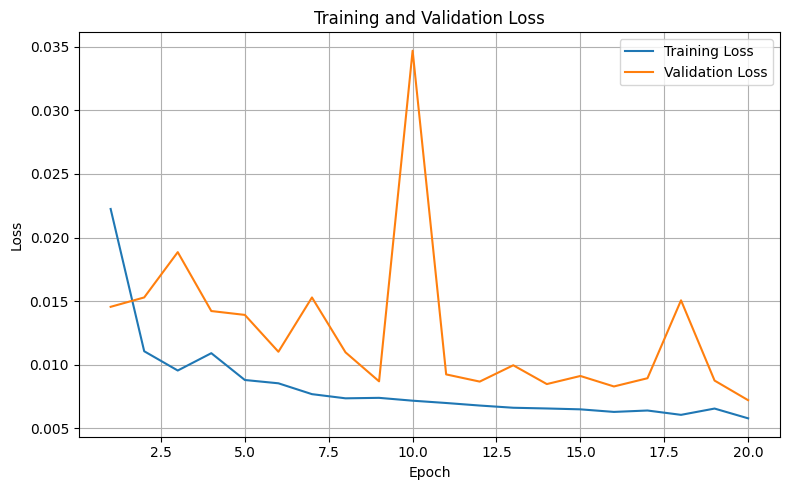

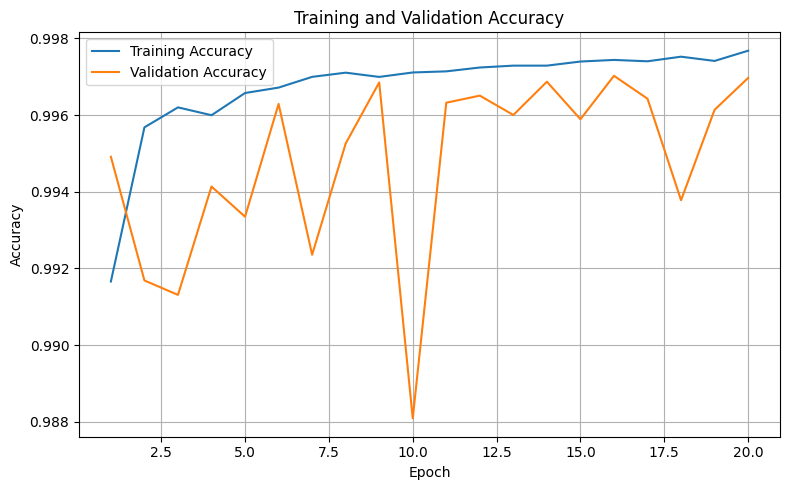

In [ ]:
# ============================================================
# Final LSTM Learning Curves
# ============================================================

import matplotlib.pyplot as plt

epochs_completed = range(1, len(train_losses) + 1)

# ============================================================
# Loss Curve
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_completed,
    train_losses,
    label="Training Loss"
)

plt.plot(
    epochs_completed,
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# Accuracy Curve
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_completed,
    train_accuracies,
    label="Training Accuracy"
)

plt.plot(
    epochs_completed,
    val_accuracies,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 42. Final Results

The final LSTM model achieved a test accuracy of **98.26%** on **162,384 unseen test sequences**.

The model achieved F1-scores of **98.11%** for the Safe class, **98.31%** for the Warning class, and **99.11%** for the Critical class.

The Critical class achieved a recall of **98.72%**, indicating that the model correctly identified **7,726 out of 7,826** critical test sequences.

Overall, the results indicate that the final model performs very well in classifying environmental conditions into Safe, Warning, and Critical risk levels.

## 43. Interpretation of Results

The confusion matrix shows that most test sequences were correctly classified.

Out of **162,384** test sequences, the model correctly classified **159,556** sequences, while **2,828** were misclassified.

Most errors occurred between neighboring risk levels, particularly between **Safe and Warning** and between **Warning and Critical**. Importantly, no Critical sequences were misclassified as Safe.

The high performance across all three classes indicates that temperature and humidity sequences contain useful temporal patterns for distinguishing between different risk levels.

## 44. Overfitting and Underfitting Analysis

The training and validation learning curves were monitored throughout model development.

The final model used early stopping based on validation loss and restored the model with the lowest validation loss. The best validation loss was **0.0080 at epoch 15**, with a validation accuracy of **99.70%**.

The training and validation performance remained relatively close toward the end of training, with no clear evidence of severe overfitting. The model also achieved strong performance on the unseen test set, supporting its ability to generalize to unseen sequences.

There is also no clear evidence of underfitting because both training and validation performance reached high levels.

## 45. Limitations

This project has several limitations.

First, the model uses only temperature and humidity as input features. Other cold-chain factors, such as storage events, equipment status, location, or additional environmental measurements, could provide additional information.

Second, the risk labels are based on predefined temperature thresholds rather than direct measurements of actual product damage or quality loss.

Finally, the dataset represents a specific sensing environment and time period, so the model should be evaluated on data from different environments and conditions before being used in a real-world cold-chain monitoring system.

## 46. Future Work

Future work could include adding additional cold-chain variables such as storage events, equipment status, location, and other relevant sensor measurements.

The model could also be evaluated using data collected from different storage environments and operating conditions.

Another possible improvement is developing a real-time monitoring system that continuously processes sensor measurements and provides early warnings when the predicted risk level increases.

## 47. Conclusion

This project developed an LSTM-based deep learning model for classifying cold-chain sensor sequences into Safe, Warning, and Critical risk levels.

After data preprocessing, exploratory analysis, sequence generation, feature scaling, model training, and architecture comparison, the final two-layer LSTM model was selected.

The final model achieved **98.26% accuracy** on the unseen test set, with strong precision, recall, and F1-scores across all three classes. The Critical class achieved an F1-score of **99.11%** and a recall of **98.72%**.

The comparison with the simpler LSTM also showed that the final model achieved a **0.51 percentage-point improvement** in test accuracy.

These results demonstrate that LSTM networks can effectively learn temporal patterns from temperature and humidity measurements for early cold-chain risk classification.